## Importation de nos données

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("cleaned_dataset.csv")


In [ ]:
df_prep = df.copy()
le_service = LabelEncoder()
df_prep["Service_encoded"] = le_service.fit_transform(df_prep["Service"])

le_dep = LabelEncoder()
df_prep["Gare_depart_encoded"] = le_dep.fit_transform(df_prep["Gare de départ"])

le_arr = LabelEncoder()
df_prep["Gare_arrivee_encoded"] = le_arr.fit_transform(df_prep["Gare d'arrivée"])


## Pourquoi encoder comme le montre le code précedent ?
> Notre modèle a besoin de nombre pour fonctionner alors on remplace les noms des gares par des nombres comme l'exemple ci dessous :
> PARIS LYON -> 0 , TOULOUSE -> 1 etc... il y a 132 gares soit 132 nombre differents 
> Notre modèle est donc prêt a fonctionner ! 

In [ ]:
features = [
    "Year",
    "Month",
    "Service_encoded",
    "Gare_depart_encoded",
    "Gare_arrivee_encoded",
    "Durée moyenne du trajet",
    "Nombre de trains annulés",
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
]

## La selection de nos features
> On selectionne nos features comme on le souhaite. On a choisit celles du haut car elles nous semblait les plus logiques on aurait plus en rajouter ou en enlever

In [49]:
X = df_prep[features]
y = df_prep["Retard moyen de tous les trains à l'arrivée"]

## On initialise notre X et y
> Notre X qui correspond a nos features et mon y notre target qui corrspond au : "Retard moyen de tous les trains à l'arrivée"

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Pourquoi on initialise X_train, X_test, y_train, y_test avec train_test_split
> Concretement avec train_test_split on peut séparter nos données "on les split" en 20 pourcents pour les tests et 80 pourcents pour l'entraîner.<br>
> Si on en le faisait pas en gros c'est comme si on entraînait notre modèle et testait notre modèle avec les mêmes informations donc ca n'aurait aucun sens parce que les resultats seraient toujours <br>parfaits. On donnes des infos pour l'entrainer puis on donne les mêmes infos pour le tester soit le meme résultat donc illogique.

In [ ]:
baseline_pred = (
    [y_train.mean()] * len(y_test)
)  # y_train.mean() -> calcule la moyenne de retard de tous les trains puis * len(y_test) la repete la taille de y_test
baseline_mae = mean_absolute_error(
    y_test, baseline_pred
)  # ici on fait la moyenne de nos erreurs entre y_test et baseline_perd et ca nous renvoie un chiffre qui represente le nombre moyen de minutes
# que on se trompe par exemple => y_test = 10 et baseline_pred = 5 => 10 - 5 = 5 -> on se trompe en moyenne de 5 minutes

## Pourquoi une base line ?
> -> La base line est la prédiction la plus stupide qui soit raisonnablement bonne : en gros c'est la moyenne de tous.<br>
> -> Par exemple : Les retards réels: [5, 10, 8, 15, 6, 12, 20] la moyenne sera : (5+10+8+15+6+12+20) / 7 soit 10.9 minutes<br>
> -> Donc la base line predit 10.9 minutes de retard pour tous les trajets<br>
> -> Ce sera donc notre moyen de comparaison avec notre modele car lui est censé faire mieux<br>
> -> Si model_mae >= baseline_mae notre modèle n'est pas du tout performant on cherche une valeur inferieure

## Pourquoi le sujet nous demande d'utiliser un modele de regression ? 
> Apres avoir regardé la documentation on a peu constater que pour un modèle qui renvoie une valeure continue il fallait utiliser un modele de regression. Sinon si notre modele devait nous renvoyer une
 categorie on aurait utiliser un modele de classification. A voir plus dans le schema de presentation et d'explication de notre powerpoint... Mais plus simplement si on predit un "Nombre" c'est regression et si on predit une "Catégorie" c'est classification.

 ## Pourquoi Random Forest et pas Linear Regression ?
 > Le sujet nous dis juste de choisir entre linear ou arbre. Apres recherche et test on a peu voir que le linear regression n'etait pas le plus optimal pour un modèle comportant beaucoup de features et de relations complexes. Nous avons donc continué avec le modèle de "Random Forest Regression".


In [ ]:
model = RandomForestRegressor(
    random_state=42
)  # on creer le modele avec notre algo RandomForest avec notre random_state = 42 pour la reproductibilité
model.fit(
    X_train, y_train
)  # on entraine ensuite notre modele avec nos X_train et y_train nos donnees d'entraienements
y_pred = model.predict(X_test)
print(
    y_pred
)  # on test ensuite notre modele avec nos donnees de test -> qui nous renvoier une liste des minutes de retards en fonction des

[ 2.8483982   9.38302553 15.95075355 ...  3.53646898  4.41571199
  4.72917124]


In [ ]:
mae = mean_absolute_error(
    y_test, y_pred
)  # pour voir notre modele de trompe de combien de minutes en moyenne
rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)  # pour voir notre modele de trompe de combien de minutes en moyenne mais en penalise plus les grosses erreurs que le mae
r2 = r2_score(
    y_test, y_pred
)  # le pourcentage de resussite de notre modele -> plus il est proche de 1 mieux c'est
print("mae:", mae)
print("rmse:", rmse)
print("r2:", r2)
# le mae doit etre inferieure a notre base_line_mae qui elle est bete et fait la moyenne :
if mae < baseline_mae:
    print(
        f"Notre modèle est bon car il se trompe en moyenne de  {mae} min et le Baseline MAE de {baseline_mae} min soit notre modele mae < baseline_mae"
    )  # on verifie si notre modele est performant en comparant le mae -> le model_mae doit etre inferieur a notre baseline_mae qui elle est bete et fait la moyenne comme dit precedemment
else:
    print(f"Notre modèle n'est pas bon : MAE = {mae}, Baseline MAE = {baseline_mae}")

mae: 1.6821543403782466
rmse: 2.593876520981338
r2: 0.6529815729760424
Notre modèle est bon car il se trompe en moyenne de  1.6821543403782466 min et le Baseline MAE de 3.299247368054526 min soit notre modele mae < baseline_mae


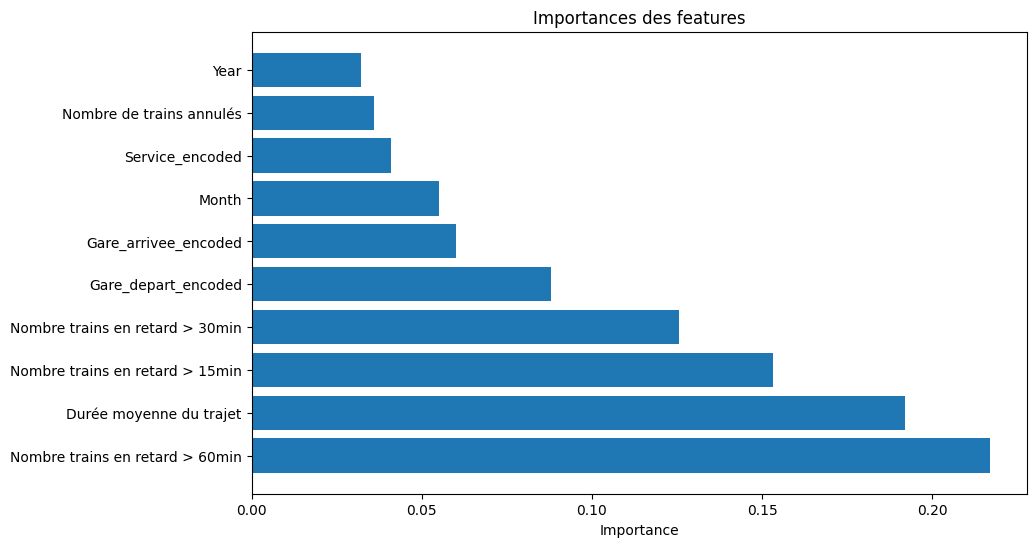

In [ ]:
feature_importance = pd.DataFrame(
    {
        "Feature": features,  # on met le nom de nos features dans une colonne de notre dataframde
        "Importance": model.feature_importances_,  # on met l'importance de chaque feature pour notre modele dans une autre colonne de notre dataframe
    }
).sort_values(
    "Importance", ascending=False
)  # on trie ensuite notre dataframe par ordre decroissant d'importance pour voir quelles sont les features les plus importantes pour notre modele

plt.figure(figsize=(10, 6))
plt.barh(feature_importance["Feature"], feature_importance["Importance"])
plt.xlabel("Importance")
plt.title("Importances des features")
plt.savefig("feature_importance.png")
plt.show()
# on visualise ensuite l'importance de chaque feature pour notre modele -> plus la barre est longue plus la feature est importante pour notre modele

## Intepretation generale de notre modèle :
> -> notre model_mae = 1.68 min. Cela veut dire que en moyenne notre modèle se trompera de 1.68 min environ sur chacunes des ses prédictions.<br>
> -> Exemple : un utilisateur donne toutes les features demandées , il aura une predicion de retard de son train à 1.68 min près. Si le modèle renvoie 12 minutes de retard il peut esperer que le retard du train soit compris entre 10 et 14 minutes en gros.<br>
> -> notre model_rmse = 2.6. Il montre les gros retards que le modèle ne predit pas bien.<br>
> -> notre model_R² = 0.65. Cela represente en gros 65 pourcents des retards sint expliqués par les features et le reste donc 35 pourcents non expliqué. Plus notre R2 est polus de 1 plus notre modele est fiable. Avec 65 pourcents nous pouvons estimer que notre modèle est qssez fiable.<br>
> -> Nous avons aussi peu voir que notre model_mae est inferieur à notre baseline_mae donc notre modèle est plutot performant. <br>
> -> Avec le schema du haut on peut voir l'importances de chaque features sur notre resultat final et on remarque que year est celui qui a le moins d'importance comparé à Nombre trains en retard > 60 min qui lui est la feature la plis importante pour notre résultat.<br>
> -> Notre modèle reste un modèle de prédiction. Sa fiabilité est liée aux données que nous avons eu le droit d'analyser. Nous n'avons pas de features imnportantes comme les heures , la meteo , les grèves etc.. qui selon nous reste les features les plus importantes. Notre dataset reste aussi assez petit il n'est pas suffisant pour des prédictions reelles.<br>

## Exportation de notre modèle

In [ ]:
joblib.dump(
    model, "model.joblib"
)  # on exporte notre modele pour l'utiliser dans le dashboard
joblib.dump(
    le_service, "encoder_service.joblib"
)  # on exporte notre encoder pour pouvoir encoder les nouvelles données dans le dashboard
joblib.dump(le_dep, "encoder_gare_dep.joblib")
joblib.dump(le_arr, "encoder_gare_arr.joblib")
joblib.dump(
    features, "features_list.joblib"
)  # on exporte la liste de nos features pour pouvoir garder l'ordre de nos features dans le dashboard